# Métodos híbridos y paralelos: algoritmos meméticos, islas y `multiprocessing`

> Notebook 13 de la serie *metaheurísticas desde cero* · Bloque 04: tópicos avanzados.
> Anterior: [12 · Optimización multiobjetivo](12-optimizacion-multiobjetivo.ipynb) ·
> Relacionadas: [09 · Algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb),
> [10 · BRKGA, meméticos y scatter search](../03-metodos-poblacionales/10-brkga-memeticos-scatter-search.ipynb),
> [03 · Búsqueda local e ILS](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb) ·
> Siguiente: [14 · Medición de desempeño](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb)

## Contenido
1. Taxonomía de híbridos
2. El problema base: QAP, con evaluación incremental (delta) del intercambio y su validación
3. Búsqueda local y algoritmo genético
4. Algoritmo memético (GA + búsqueda local): comparación por generaciones, tiempo e instancia
5. Un híbrido con "programación exacta" en miniatura (matheuristic)
6. Paralelismo: taxonomía, ley de Amdahl, `multiprocessing` en un notebook (macOS y Linux)
7. Multi-start paralelo, maestro-esclavo y modelo de islas (simulado vs paralelo real)
8. Resumen, ejercicios, referencias

## Qué vas a aprender / Prerrequisitos

**Aprenderás a**
- clasificar un híbrido (nivel de acoplamiento, secuencial o cooperativo) y a elegir con qué combinar una metaheurística;
- implementar un algoritmo memético y evaluar **honestamente** su beneficio (por generación, por tiempo y por instancia);
- calcular el *delta* de un intercambio en QAP en $O(n)$ y validarlo contra la recomputación completa;
- paralelizar con `multiprocessing` sin caer en los problemas de `spawn` en macOS, y medir speedup/eficiencia contra la ley de Amdahl;
- comprobar que un modelo de islas paralelo reproduce **exactamente** el simulado secuencialmente.

**Prerrequisitos:** GA (selección, cruce OX, mutación), búsqueda local por vecindarios, NumPy básico.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time, os, sys, inspect, tempfile, multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from scipy.stats import wilcoxon

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
t_inicio_notebook = time.time()
print("núcleos lógicos:", os.cpu_count(), "| método de arranque por defecto:", mp.get_start_method())

núcleos lógicos: 14 | método de arranque por defecto: spawn


## 1. Taxonomía de híbridos

Una **metaheurística híbrida** combina componentes de distinta naturaleza para compensar debilidades: las poblacionales exploran bien pero convergen lento en el detalle; las de trayectoria intensifican bien pero se atascan; los métodos exactos son óptimos en subproblemas pequeños pero no escalan.

Dos ejes clásicos para clasificar (Talbi, 2002; Raidl, 2006):

| Eje | Opciones |
|---|---|
| **Nivel** | *bajo* (una función de un método se reemplaza por otro método, p. ej. la mutación de un GA por una búsqueda local) frente a *alto* (los métodos conservan su identidad y cooperan) |
| **Ejecución** | *relevo* (*relay*: uno tras otro, secuencial) frente a *trabajo en equipo* (*teamwork*: en paralelo y cooperando) |

La combinación da cuatro clases: LRH, LTH, HRH, HTH (por *low/high-level relay/teamwork hybrid*). Un **GA + búsqueda local** sobre cada hijo es un LRH (relevo a bajo nivel) y es el algoritmo **memético**; un **modelo de islas con distintos algoritmos** es un HTH.

### ¿Con qué se combina una metaheurística?

| Combinación | Idea | Ejemplos |
|---|---|---|
| **Meta + meta** | una explora, otra intensifica; o poblacional + trayectoria | memético (GA+LS), GRASP+*path relinking*, ILS dentro de un GA, SA para refinar la mejor solución de PSO |
| **Meta + programación matemática** (*matheuristics*) | usar solvers exactos (PL/PLE) como subrutinas o relajaciones | LNS con subproblemas resueltos por MIP, *fix-and-optimize*, *relax-and-fix*, *kernel search*, columnas generadas guiadas por una metaheurística, cotas duales para podar |
| **Meta + restricciones** (CP) | propagación de restricciones para mantener factibilidad y podar el vecindario | LNS con CP (Shaw, 1998), búsqueda local sobre soluciones factibles de CP |
| **Meta + aprendizaje automático** | aprender del historial de búsqueda, o usar ML como componente | selección adaptativa de operadores (bandidos), *surrogates* para evaluar rápido, EDA (modelos probabilísticos), predecir qué vecinos prometen; y a la inversa, metaheurísticas para ML ([16](../06-aplicacion-ml/16-hiperparametros-ml-metaheuristicas.ipynb), [17](../06-aplicacion-ml/17-seleccion-de-caracteristicas-metaheuristicas.ipynb)) |

En este notebook implementamos el primero (memético) y una miniatura del segundo (reoptimización **exacta** de un subconjunto, con enumeración en lugar de un solver MIP).

## 2. Problema base: Quadratic Assignment Problem (QAP)

Hay $n$ instalaciones y $n$ localizaciones. $F_{ij}$ es el flujo entre las instalaciones $i$ y $j$; $D_{ab}$ la distancia entre las localizaciones $a$ y $b$. Una asignación es una permutación $p$ (la instalación $i$ va a la localización $p_i$):
$$C(p)=\sum_{i=1}^n\sum_{j=1}^n F_{ij}\,D_{p_ip_j}.$$
Es NP-difícil (incluso aproximar es muy difícil) y un banco de pruebas estándar para híbridos.

### Delta de un intercambio
Intercambiar las localizaciones de $r$ y $s$ cambia solo los términos que involucran a $r$ o $s$. Con $p'=p\circ(r\,s)$ (Taillard, 1991):
$$\Delta(p,r,s)=\underbrace{(F_{rr}-F_{ss})(D_{p_sp_s}-D_{p_rp_r})+(F_{rs}-F_{sr})(D_{p_sp_r}-D_{p_rp_s})}_{\text{términos propios}}+\sum_{k\ne r,s}\Big[(F_{kr}-F_{ks})(D_{p_kp_s}-D_{p_kp_r})+(F_{rk}-F_{sk})(D_{p_sp_k}-D_{p_rp_k})\Big].$$
Esto cuesta $O(n)$ en lugar de $O(n^2)$ para recomputar $C(p')$. Todo el vecindario ($\binom n2$ intercambios) cuesta $O(n^3)$ con este método, pero se puede obtener **vectorizado** con productos matriciales: con $D^p_{ij}=D_{p_ip_j}$, las sumas sobre $k$ son entradas de $F^\top D^p$ y $FD^{p\top}$ (restando los términos $k=r,s$ que sobran). Implementamos ambas y las validamos contra la recomputación completa, para matrices **simétricas y asimétricas**.

In [2]:
def crear_instancia(n, seed, simetrica=True):
    '''Matrices de flujo F y distancia D aleatorias, enteras, diagonal nula.'''
    r = np.random.default_rng(seed)
    F = r.integers(0, 10, (n, n)).astype(float)
    D = r.integers(1, 30, (n, n)).astype(float)
    if simetrica:
        F = np.triu(F, 1); F = F + F.T
        D = np.triu(D, 1); D = D + D.T
    else:
        np.fill_diagonal(F, 0); np.fill_diagonal(D, 0)
    return F, D

def costo(p, F, D):
    '''Costo QAP completo: sum_ij F_ij * D[p_i, p_j].  O(n^2).'''
    return float((F * D[np.ix_(p, p)]).sum())

def delta_swap(p, F, D, r, s):
    '''Delta (costo nuevo - costo actual) de intercambiar las localizaciones de r y s. O(n).'''
    pr, ps = p[r], p[s]
    d = (F[r, r] - F[s, s]) * (D[ps, ps] - D[pr, pr]) + (F[r, s] - F[s, r]) * (D[ps, pr] - D[pr, ps])
    k = np.ones(len(p), bool); k[[r, s]] = False
    pk = p[k]
    d += ((F[k, r] - F[k, s]) * (D[pk, ps] - D[pk, pr]) + (F[r, k] - F[s, k]) * (D[ps, pk] - D[pr, pk])).sum()
    return d

def delta_matrix(p, F, D):
    '''Matriz (n x n) con delta_swap(p, r, s) para todo par, vectorizada con dos productos matriciales.'''
    Dp = D[np.ix_(p, p)]
    M = F.T @ Dp; N = F @ Dp.T
    dM, dN = np.diag(M), np.diag(N)
    S = (M + M.T - dM[:, None] - dM[None, :]) + (N + N.T - dN[:, None] - dN[None, :])   # suma sobre todo k
    Frr = np.diag(F)[:, None] * np.ones_like(F); Fss = Frr.T
    Drr = np.diag(Dp)[:, None] * np.ones_like(F); Dss = Drr.T
    # se descuentan los términos k=r y k=s (ya van en "términos propios")
    T1r = (Frr - F) * (Dp - Drr);     T2r = (Frr - F.T) * (Dp.T - Drr)
    T1s = (F.T - Fss) * (Dss - Dp.T); T2s = (F - Fss) * (Dss - Dp)
    propios = (Frr - Fss) * (Dss - Drr) + (F - F.T) * (Dp.T - Dp)
    return propios + S - T1r - T2r - T1s - T2s

In [3]:
# --- Validación: delta O(n), delta vectorizado y recomputación completa deben coincidir EXACTAMENTE (datos enteros)
max_err = 0.0; n_pares = 0
for simetrica in (True, False):
    for n, seed in [(8, 0), (15, 1), (25, 2)]:
        F, D = crear_instancia(n, seed, simetrica)
        rng = np.random.default_rng(seed)
        for _ in range(5):
            p = rng.permutation(n); c0 = costo(p, F, D)
            DM = delta_matrix(p, F, D)
            for r in range(n):
                for s in range(r + 1, n):
                    q = p.copy(); q[[r, s]] = q[[s, r]]
                    real = costo(q, F, D) - c0
                    max_err = max(max_err, abs(real - delta_swap(p, F, D, r, s)), abs(real - DM[r, s]))
                    n_pares += 1
print(f"{n_pares} pares (r,s) verificados (matrices simétricas y asimétricas); error máximo = {max_err}")
assert max_err == 0.0
# simetría del vecindario: delta(r,s) == delta(s,r)
print("delta_matrix simétrica en r,s:", np.allclose(DM, DM.T))

4330 pares (r,s) verificados (matrices simétricas y asimétricas); error máximo = 0.0
delta_matrix simétrica en r,s: True


La ventaja es de velocidad. Medimos el coste de evaluar **todo** el vecindario de intercambios de dos formas: recomputando cada vecino por completo, y con la matriz de deltas.

In [4]:
F, D = crear_instancia(30, 1); p = np.random.default_rng(0).permutation(30); n = 30
iu = np.triu_indices(n, 1)

def vecindario_completo(p):
    c0 = costo(p, F, D); out = []
    for r, s in zip(*iu):
        q = p.copy(); q[[r, s]] = q[[s, r]]; out.append(costo(q, F, D) - c0)
    return np.array(out)

t = time.time(); [vecindario_completo(p) for _ in range(20)]; t_full = (time.time() - t) / 20
t = time.time(); [delta_matrix(p, F, D) for _ in range(500)]; t_mat = (time.time() - t) / 500
t = time.time(); [[delta_swap(p, F, D, r, s) for r, s in zip(*iu)] for _ in range(20)]; t_o_n = (time.time() - t) / 20
assert np.allclose(vecindario_completo(p), delta_matrix(p, F, D)[iu])
print(f"vecindario de {len(iu[0])} swaps (n=30):  recomputar = {t_full*1e3:.1f} ms | delta O(n) en bucle = {t_o_n*1e3:.1f} ms | matriz de deltas = {t_mat*1e3:.3f} ms")
print(f"aceleración de la versión matricial vs recomputar: x{t_full/t_mat:.0f}")

vecindario de 435 swaps (n=30):  recomputar = 5.6 ms | delta O(n) en bucle = 7.7 ms | matriz de deltas = 0.072 ms
aceleración de la versión matricial vs recomputar: x79


## 3. Búsqueda local y algoritmo genético para QAP

**Búsqueda local (mejor mejora):** en cada iteración se calcula la matriz de deltas, se toma el swap de menor delta y se aplica si mejora; se detiene en un óptimo local respecto al vecindario 2-swap.

**GA:** población de permutaciones, torneo binario, cruce **OX** (*order crossover*: copia un segmento del padre 1 y rellena con el orden del padre 2), mutación por intercambio con probabilidad $p_m$ y reemplazo $(\mu+\lambda)$ elitista. El **memético** aplica la búsqueda local a cada hijo (adaptación *lamarckiana*: el hijo mejorado reemplaza al original) y a la población inicial.
```
GA(pop, G):
    P ← población aleatoria; (memético: P ← LS(P))
    repetir G veces:
        para cada uno de pop hijos:
            padres ← torneo binario ×2;  h ← OX(padres);  mutar con prob. pm
            (memético: h ← búsqueda_local(h))
        P ← los pop mejores de P ∪ hijos
```

In [5]:
def busqueda_local(p, F, D, c=None, max_iter=1000):
    '''Mejor-mejora con vecindario 2-swap y matriz de deltas. Devuelve (permutación, costo).'''
    p = p.copy(); c = costo(p, F, D) if c is None else c
    iu = np.triu_indices(len(p), 1)
    for _ in range(max_iter):
        dm = delta_matrix(p, F, D)[iu]
        k = int(np.argmin(dm))
        if dm[k] >= -1e-9: break                      # óptimo local
        r, s = iu[0][k], iu[1][k]
        p[[r, s]] = p[[s, r]]; c += dm[k]
    return p, c

def ox(p1, p2, rng):
    '''Order crossover: segmento de p1, resto en el orden de p2. Devuelve siempre una permutación.'''
    n = len(p1); a, b = np.sort(rng.choice(n, 2, replace=False))
    h = -np.ones(n, dtype=int); h[a:b + 1] = p1[a:b + 1]
    usado = np.zeros(n, bool); usado[p1[a:b + 1]] = True
    h[h < 0] = p2[~usado[p2]]
    return h

def inicializar_poblacion(F, D, pop, rng, memetico=False):
    P = np.array([rng.permutation(len(F)) for _ in range(pop)])
    C = np.array([costo(p, F, D) for p in P])
    if memetico:
        for i in range(pop): P[i], C[i] = busqueda_local(P[i], F, D, C[i])
    return P, C

def evolucionar(P, C, F, D, gens, rng, memetico=False, pm=0.2, pls=1.0):
    '''Avanza 'gens' generaciones (mu+lambda). Devuelve (P, C, historial del mejor costo por generación).'''
    pop, n = len(P), len(F)
    hist = np.empty(gens)
    for g in range(gens):
        hijos, ch = [], []
        for _ in range(pop):
            a = rng.integers(pop, size=2); i = a[np.argmin(C[a])]        # torneo binario
            a = rng.integers(pop, size=2); j = a[np.argmin(C[a])]
            h = ox(P[i], P[j], rng)
            if rng.random() < pm:
                x, y = rng.choice(n, 2, replace=False); h[[x, y]] = h[[y, x]]
            ch_h = costo(h, F, D)
            if memetico and rng.random() < pls: h, ch_h = busqueda_local(h, F, D, ch_h)
            hijos.append(h); ch.append(ch_h)
        P2 = np.vstack([P, hijos]); C2 = np.concatenate([C, ch])
        o = np.argsort(C2, kind="stable")[:pop]
        P, C = P2[o], C2[o]
        hist[g] = C.min()
    return P, C, hist

def ga(F, D, pop, gens, rng, memetico=False, **kw):
    P, C = inicializar_poblacion(F, D, pop, rng, memetico)
    h0 = C.min()                                   # mejor costo inicial (generación 0)
    P, C, hist = evolucionar(P, C, F, D, gens, rng, memetico, **kw)
    return P, C, np.concatenate([[h0], hist])

In [6]:
# --- Validaciones de correctitud
F, D = crear_instancia(25, 5); rng = np.random.default_rng(0)
# 1) OX produce permutaciones válidas
for _ in range(500):
    a, b = rng.permutation(25), rng.permutation(25)
    assert sorted(ox(a, b, rng)) == list(range(25))
# 2) la búsqueda local devuelve permutación, costo coherente con la recomputación y nunca empeora
for _ in range(20):
    p0 = rng.permutation(25); p1, c1 = busqueda_local(p0, F, D)
    assert sorted(p1) == list(range(25)) and abs(c1 - costo(p1, F, D)) < 1e-9 and c1 <= costo(p0, F, D)
    assert delta_matrix(p1, F, D)[np.triu_indices(25, 1)].min() >= -1e-9      # óptimo local 2-swap
# 3) el GA devuelve población de permutaciones con costos coherentes y el mejor es monótono (elitismo)
for mem in (False, True):
    P, C, h = ga(F, D, 20, 15, rng, memetico=mem)
    assert all(sorted(p) == list(range(25)) for p in P)
    assert np.allclose(C, [costo(p, F, D) for p in P]) and np.all(np.diff(h) <= 0)
print("OX, búsqueda local, GA y memético: validados (permutaciones, costos coherentes, elitismo, óptimo local)")

OX, búsqueda local, GA y memético: validados (permutaciones, costos coherentes, elitismo, óptimo local)


## 4. GA frente a GA híbrido (memético)

**Diseño del experimento.** Tres instancias aleatorias ($n=20,30,40$), 8 semillas por instancia y población 30.
- `GA`: 60 generaciones.
- `Memético`: 60 generaciones (cada hijo pasa por la búsqueda local).
- `GA largo`: 600 generaciones, para **emparejar aproximadamente el tiempo de cómputo** del memético (la búsqueda local no es gratis: el memético tarda más por generación).

No hay óptimo conocido: el *gap* se mide contra el **mejor costo hallado por cualquier corrida** en esa instancia, que es una cota superior del óptimo (por eso los gaps son optimistas).

In [7]:
instancias = {20: 11, 30: 12, 40: 13}
SEMILLAS = range(8)
POP, GENS, GENS_LARGO = 30, 60, 600
res = {}     # (n, algoritmo) -> dict(hist=[...], tiempos=[...], final=[...])
for n, sd in instancias.items():
    F, D = crear_instancia(n, sd)
    for nombre, kw in [("GA", dict(gens=GENS, mem=False)), ("Memético", dict(gens=GENS, mem=True)),
                       ("GA largo", dict(gens=GENS_LARGO, mem=False))]:
        H, T = [], []
        for s in SEMILLAS:
            rng = np.random.default_rng(1000 * n + s)
            t0 = time.time()
            P, C, h = ga(F, D, POP, kw["gens"], rng, memetico=kw["mem"])
            T.append(time.time() - t0); H.append(h)
        res[(n, nombre)] = dict(hist=np.array(H), t=np.array(T))
for n in instancias:
    print(f"n={n}: tiempo medio por corrida  GA {res[(n,'GA')]['t'].mean():.2f}s | Memético {res[(n,'Memético')]['t'].mean():.2f}s | GA largo {res[(n,'GA largo')]['t'].mean():.2f}s")

n=20: tiempo medio por corrida  GA 0.07s | Memético 0.39s | GA largo 0.75s
n=30: tiempo medio por corrida  GA 0.08s | Memético 1.47s | GA largo 1.66s
n=40: tiempo medio por corrida  GA 0.21s | Memético 2.20s | GA largo 0.94s


In [8]:
import pandas as pd
filas = []
for n in instancias:
    mejor = min(res[(n, a)]["hist"][:, -1].min() for a in ("GA", "Memético", "GA largo"))
    for a in ("GA", "Memético", "GA largo"):
        fin = res[(n, a)]["hist"][:, -1]
        res[(n, a)]["gap"] = 100 * (res[(n, a)]["hist"] - mejor) / mejor
        filas.append(dict(n=n, algoritmo=a, mejor_global=mejor, costo_medio=fin.mean(), gap_medio_pct=100 * (fin.mean() - mejor) / mejor,
                          gap_std_pct=100 * fin.std() / mejor, tiempo_s=res[(n, a)]["t"].mean()))
tab = pd.DataFrame(filas).set_index(["n", "algoritmo"])
print(tab.round(3).to_string())
print()
for n in instancias:
    m = res[(n, "Memético")]["hist"][:, -1]
    for rival in ("GA", "GA largo"):
        g = res[(n, rival)]["hist"][:, -1]
        print(f"n={n}: Memético vs {rival:8s}: Memético mejor en {np.sum(m < g)}/8 semillas, empata {np.sum(m == g)}; Wilcoxon p = {wilcoxon(m, g).pvalue:.3f}")

              mejor_global  costo_medio  gap_medio_pct  gap_std_pct  tiempo_s
n  algoritmo                                                                 
20 GA              18728.0     20605.00         10.022        1.767     0.069
   Memético        18728.0     18959.00          1.233        0.635     0.386
   GA largo        18728.0     19813.50          5.796        0.707     0.750
30 GA              52098.0     56442.25          8.339        1.183     0.080
   Memético        52098.0     52479.50          0.732        0.630     1.472
   GA largo        52098.0     54390.75          4.401        0.572     1.664
40 GA              89864.0     98201.25          9.278        1.098     0.211
   Memético        89864.0     90397.75          0.594        0.405     2.202
   GA largo        89864.0     93756.25          4.331        0.438     0.943

n=20: Memético vs GA      : Memético mejor en 8/8 semillas, empata 0; Wilcoxon p = 0.008
n=20: Memético vs GA largo: Memético mejor en 8/8 se

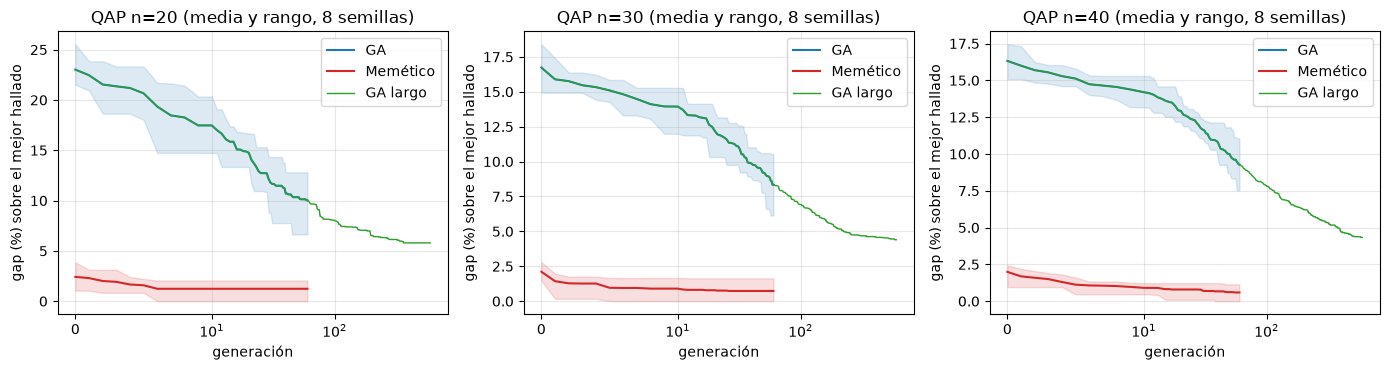

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, n in zip(axs, instancias):
    for a, c in [("GA", "C0"), ("Memético", "C3")]:
        g = res[(n, a)]["gap"]; x = np.arange(g.shape[1])
        ax.plot(x, g.mean(0), c=c, label=a); ax.fill_between(x, g.min(0), g.max(0), color=c, alpha=.15)
    g = res[(n, "GA largo")]["gap"]
    ax.plot(np.arange(g.shape[1]), g.mean(0), c="C2", label="GA largo", lw=1)
    ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("generación"); ax.set_ylabel("gap (%) sobre el mejor hallado")
    ax.set_title(f"QAP n={n} (media y rango, 8 semillas)"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura (contrasta con la tabla y los tests impresos).**
- **Por generación**, el memético domina de forma clara: cada generación cuesta más pero cada hijo ya es un óptimo local. Los tests de Wilcoxon impresos lo confirman (gana en todas las semillas de las tres instancias).
- **Por tiempo**, el GA largo recibe un tiempo comparable (en $n=20$ y $n=30$ incluso mayor que el del memético, ver tiempos impresos; en $n=40$ algo menor). Aun así sigue lejos del memético en gap: en esta configuración la búsqueda local aporta algo que más generaciones de GA no logran.
- Cuidado: el resultado depende de la implementación (el GA es Python puro; la búsqueda local está vectorizada con la matriz de deltas). Una conclusión de ingeniería sólida requiere medir en tu propio entorno y con tu propia instancia.

## 5. Un híbrido con optimización exacta en miniatura (*matheuristic*)

El esquema de las *matheuristics* (Maniezzo, Stützle, Voß, 2010) incorpora un solver exacto como **subrutina de una metaheurística**: escoger un subproblema pequeño y resolverlo a optimalidad (LNS, *fix-and-optimize*). Aquí lo hacemos en miniatura: dado un óptimo local 2-swap, escogemos $k=4$ instalaciones al azar, **fijamos las demás** y enumeramos las $k!=24$ reasignaciones de sus localizaciones. Es un vecindario *mucho más grande* que el swap ($k!$ vecinos, no $\binom n2$), explorado de forma exacta.

La pregunta práctica: ¿encuentra mejoras que la búsqueda local 2-swap no puede ver?

In [10]:
from itertools import permutations

def reoptimizar_exacto(p, F, D, k, rng, c=None):
    '''Elige k instalaciones al azar, fija el resto y busca el MEJOR reacomodo de esas k localizaciones por enumeración.'''
    c = costo(p, F, D) if c is None else c
    idx = rng.choice(len(p), k, replace=False)
    locs = p[idx].copy()
    mejor_c, mejor_p = c, p
    for perm in permutations(range(k)):
        q = p.copy(); q[idx] = locs[list(perm)]
        cq = costo(q, F, D)
        if cq < mejor_c - 1e-9: mejor_c, mejor_p = cq, q
    return mejor_p, mejor_c

F, D = crear_instancia(30, 12); rng = np.random.default_rng(0)
mejoras, rel = 0, []
ARRANQUES, INTENTOS = 30, 60
t0 = time.time()
for _ in range(ARRANQUES):
    p, c = busqueda_local(rng.permutation(30), F, D)          # óptimo local 2-swap
    c_ini = c; hubo = False
    for _ in range(INTENTOS):
        p2, c2 = reoptimizar_exacto(p, F, D, 4, rng, c)
        if c2 < c - 1e-9:
            hubo = True; p, c = busqueda_local(p2, F, D, c2)  # vuelve a un óptimo local 2-swap
    mejoras += hubo; rel.append(100 * (c_ini - c) / c_ini)
    assert sorted(p) == list(range(30)) and abs(c - costo(p, F, D)) < 1e-6
print(f"{mejoras}/{ARRANQUES} óptimos locales 2-swap fueron mejorados por la reoptimización exacta de 4 instalaciones")
print(f"mejora relativa de costo (solo en los mejorados): media = {np.mean([r for r in rel if r > 0]) if mejoras else 0:.2f} %  | tiempo {time.time()-t0:.1f}s")

6/30 óptimos locales 2-swap fueron mejorados por la reoptimización exacta de 4 instalaciones
mejora relativa de costo (solo en los mejorados): media = 1.00 %  | tiempo 0.5s


El conteo anterior (distinto de cero) muestra que una parte de los óptimos locales 2-swap **no son óptimos** respecto a un vecindario más amplio: el subproblema exacto encuentra mejoras que el swap no ve, aunque la mejora relativa por arranque sea modesta (ver el porcentaje impreso). Ese es el valor de combinar vecindarios de distinta escala (como en [VNS/LNS](../01-metodos-de-trayectoria/04-vns-lns.ipynb)). Con un solver MIP real se pueden reoptimizar subproblemas bastante más grandes que $k=4$.

## 6. Paralelismo

### Taxonomía
| Modelo | Qué se paraleliza | Cambia el algoritmo | Comunicación |
|---|---|---|---|
| **Paralelismo de evaluación** (maestro-esclavo) | evaluar/mejorar individuos de una generación | no (resultado idéntico) | cada generación |
| **Multi-start independiente** | ejecuciones completas con semillas distintas | no | solo al final (reducción) |
| **Modelo de islas** | subpoblaciones que evolucionan por separado | **sí** | migración periódica de individuos |
| **Celular / difusión** | individuos en una malla con vecinos locales | sí | local, continua |

### Ley de Amdahl
Si una fracción $f$ del trabajo es secuencial (no paralelizable), el *speedup* con $p$ procesadores es
$$S(p)=\frac{T_1}{T_p}=\frac{1}{f+\frac{1-f}{p}}\ \le\ \frac1f,\qquad E(p)=\frac{S(p)}{p}.$$
Incluso con $f=5\%$ nunca se supera $20\times$. La **ley de Gustafson** matiza: si al tener más procesadores se aumenta el tamaño del problema (más iteraciones o población), la fracción secuencial relativa decrece, $S(p)=p-f(p-1)$. En metaheurísticas, el coste fijo suele ser el arranque de procesos, la serialización (*pickle*) de datos y la sincronización.

### `multiprocessing` dentro de un notebook (el problema de macOS)
En macOS (y Windows) el método de arranque por defecto es **`spawn`**: el proceso hijo es un intérprete nuevo que debe poder *importar* las funciones que va a ejecutar. Las funciones definidas en celdas de un notebook viven en `__main__` del kernel y el hijo no las encuentra (o falla al hacer *pickle*). Tres soluciones:
1. `mp.get_context("fork")`: los hijos heredan la memoria (solo Unix; en macOS puede ser inestable con ciertas librerías/hilos).
2. Poner las funciones en un **módulo importable** (la solución portable). Es lo que hacemos: escribimos un módulo temporal desde la propia celda, reutilizando el código fuente de las funciones ya definidas arriba con `inspect.getsource`, y lo importamos tanto en el kernel como (por `sys.path`) en los hijos.
3. En scripts: protección `if __name__ == "__main__":`.

Además: las funciones objetivo deben ser **top-level** (picklables) y los argumentos/retornos, pequeños, porque cada llamada serializa datos.

In [11]:
# ---- Módulo temporal con las funciones de trabajo (importable por los procesos hijos) ----
MOD_DIR = tempfile.mkdtemp(prefix="qap_paralelo_")
nucleo = [costo, delta_matrix, busqueda_local, ox, inicializar_poblacion, evolucionar]
fuente = "import numpy as np\n\n" + "\n\n".join(inspect.getsource(f) for f in nucleo) + '''

# ---------------- tareas que se ejecutan en los procesos hijos ----------------
def tarea_multistart(args):
    F, D, semilla, pop, gens = args
    rng = np.random.default_rng(semilla)
    P, C = inicializar_poblacion(F, D, pop, rng, True)
    P, C, h = evolucionar(P, C, F, D, gens, rng, True)
    return float(C.min())

def tarea_ls_bloque(args):
    perms, F, D = args
    return [busqueda_local(p, F, D) for p in perms]

def tarea_costo_bloque(args):
    perms, F, D = args
    return [costo(p, F, D) for p in perms]

def tarea_isla(args):
    P, C, rng, F, D, gens, memetico = args
    P, C, h = evolucionar(P, C, F, D, gens, rng, memetico)
    return P, C, rng
'''
with open(os.path.join(MOD_DIR, "qap_workers.py"), "w") as fh:
    fh.write(fuente)
sys.path.insert(0, MOD_DIR)
import qap_workers

# la versión del módulo debe dar exactamente el mismo resultado que la de la celda
F, D = crear_instancia(20, 3)
a = qap_workers.tarea_multistart((F, D, 5, 10, 5))
rng = np.random.default_rng(5); P, C = inicializar_poblacion(F, D, 10, rng, True); P, C, _ = evolucionar(P, C, F, D, 5, rng, True)
assert a == C.min()
print("módulo temporal creado en", MOD_DIR, "| mismo resultado que en el notebook:", a == C.min())

CTX = mp.get_context("spawn")        # el método por defecto de macOS; también funciona en Linux
def crear_pool(w):
    pool = ProcessPoolExecutor(max_workers=w, mp_context=CTX)
    list(pool.map(qap_workers.tarea_costo_bloque, [([np.arange(4)], np.eye(4), np.eye(4))] * w))   # calentamiento: arranca los w hijos
    return pool
pool_prueba = crear_pool(2)
print("pool spawn de prueba funcionando:", list(pool_prueba.map(qap_workers.tarea_costo_bloque, [([np.arange(3)], np.ones((3, 3)), np.ones((3, 3)))])))
pool_prueba.shutdown()

módulo temporal creado en /var/folders/df/0rxldt4j7251blvf755n94p40000gn/T/qap_paralelo_zvs4l7cf | mismo resultado que en el notebook: True


pool spawn de prueba funcionando: [[9.0]]


## 7. Experimentos de paralelismo

### 7.1 Multi-start independiente (el caso ideal)
Ejecutamos $K=24$ memético completos (semillas distintas, $n=40$) y medimos el tiempo con 1, 2, 4 y 8 procesos. Cada tarea es independiente: solo hay que recoger al final el mejor costo (la parte secuencial es mínima). Se mide el mínimo de 2 repeticiones para reducir ruido y el speedup se define como $T(1)/T(p)$ con el mismo tipo de pool (así la comparación incluye los mismos costes de arranque y serialización). Los tiempos de pared dependen de la carga de la máquina: son una medición, no una constante.

In [12]:
Fp, Dp_ = crear_instancia(40, 99)
K = 24
tareas = [(Fp, Dp_, 500 + s, 30, 25) for s in range(K)]

t0 = time.time(); ref = [qap_workers.tarea_multistart(t) for t in tareas]; T_seq = time.time() - t0
print(f"secuencial (sin pool): {T_seq:.2f}s  | mejor costo de los {K} multi-start = {min(ref):.0f}")

def medir(w, reps=2):
    pool = crear_pool(w); mejor_t = np.inf
    for _ in range(reps):
        t0 = time.time(); out = list(pool.map(qap_workers.tarea_multistart, tareas, chunksize=1)); mejor_t = min(mejor_t, time.time() - t0)
        assert out == ref                      # mismo resultado que el secuencial (determinista por semilla)
    pool.shutdown(); return mejor_t

W = [1, 2, 4, 8]
T = {w: medir(w) for w in W}
# speedup respecto al pool de 1 proceso (mismas condiciones de arranque/serialización)
S = {w: T[1] / T[w] for w in W}; E = {w: S[w] / w for w in W}
print(f"(referencia secuencial sin pool: {T_seq:.2f}s; la carga de la máquina durante la medición afecta a los tiempos)")
for w in W: print(f"w={w}: T={T[w]:6.2f}s  speedup={S[w]:5.2f}  eficiencia={E[w]:.2f}")

secuencial (sin pool): 17.98s  | mejor costo de los 24 multi-start = 91576


(referencia secuencial sin pool: 17.98s; la carga de la máquina durante la medición afecta a los tiempos)
w=1: T= 13.77s  speedup= 1.00  eficiencia=1.00
w=2: T=  7.52s  speedup= 1.83  eficiencia=0.92
w=4: T=  5.17s  speedup= 2.67  eficiencia=0.67
w=8: T=  3.90s  speedup= 3.53  eficiencia=0.44


fracciones secuenciales implícitas por w: [0.092 0.167 0.181] -> f media = 0.147


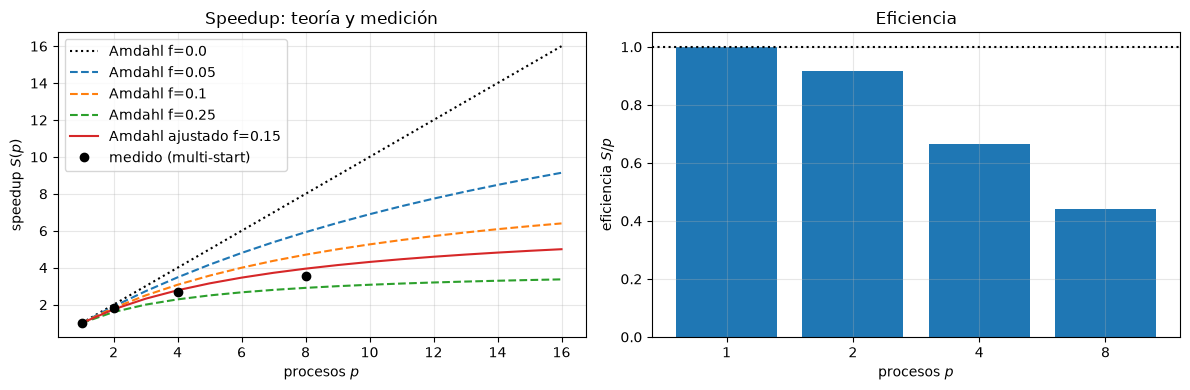

In [13]:
def f_amdahl(S, w):
    '''Fracción secuencial implícita de un speedup medido: f = (1/S - 1/w)/(1 - 1/w).'''
    return (1 / S - 1 / w) / (1 - 1 / w)

fs = [f_amdahl(S[w], w) for w in W if w > 1]
f_hat = float(np.clip(np.mean(fs), 0, 1))
print("fracciones secuenciales implícitas por w:", np.round(fs, 3), "-> f media =", round(f_hat, 3))

ps = np.arange(1, 17)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for f, st in [(0.0, "k:"), (0.05, "--"), (0.1, "--"), (0.25, "--")]:
    axs[0].plot(ps, 1 / (f + (1 - f) / ps), st, label=f"Amdahl f={f}")
axs[0].plot(ps, 1 / (f_hat + (1 - f_hat) / ps), "C3-", lw=1.5, label=f"Amdahl ajustado f={f_hat:.2f}")
axs[0].plot(W, [S[w] for w in W], "ko", label="medido (multi-start)")
axs[0].set_xlabel("procesos $p$"); axs[0].set_ylabel("speedup $S(p)$"); axs[0].set_title("Speedup: teoría y medición"); axs[0].legend()
axs[1].bar([str(w) for w in W], [E[w] for w in W], color="C0"); axs[1].axhline(1, c="k", ls=":")
axs[1].set_xlabel("procesos $p$"); axs[1].set_ylabel("eficiencia $S/p$"); axs[1].set_title("Eficiencia")
plt.tight_layout(); plt.show()

**Lectura.** Las tareas son independientes, así que el speedup debería acercarse al ideal hasta agotar los núcleos "rápidos". Las desviaciones se explican por: (i) arranque y serialización de datos (parte secuencial), (ii) **desbalance de carga** (24 tareas no se reparten parejo entre 8 procesos, y la última tarea fija el tiempo total), (iii) en CPU con núcleos heterogéneos, los procesos extra caen en núcleos más lentos, y (iv) la memoria/turbo. Compara las fracciones secuenciales implícitas impresas: si no son constantes entre $w$, es señal de que Amdahl (que supone una fracción fija) es un modelo simplificado y que hay sobrecarga que crece con $p$.

### 7.2 Maestro-esclavo: paralelizar la evaluación
Paralelizar la evaluación de los individuos de una generación **no cambia el algoritmo**, pero solo paga si cada evaluación es costosa frente al coste de enviar el individuo al otro proceso. Comparamos dos "evaluaciones" sobre 240 permutaciones de $n=40$:
- **barata**: el costo QAP (microsegundos);
- **cara**: mejorar la permutación con búsqueda local (milisegundos), como en un memético.

In [14]:
rng = np.random.default_rng(7)
perms = [rng.permutation(40) for _ in range(240)]
WPOOL = 8
pool = crear_pool(WPOOL)

def en_bloques(lst, w, bloques_por_worker):
    nb = w * bloques_por_worker
    return [lst[i::nb] for i in range(nb)]

filas = []
# --- evaluación barata
t0 = time.time(); ref_c = [costo(p, Fp, Dp_) for p in perms]; t_seq_c = time.time() - t0
for bpw in (1, 4):
    bl = en_bloques(perms, WPOOL, bpw); t0 = time.time()
    out = list(pool.map(qap_workers.tarea_costo_bloque, [(b, Fp, Dp_) for b in bl])); t = time.time() - t0
    filas.append(("costo QAP (barata)", f"{len(bl)} bloques", t_seq_c, t))
# --- evaluación cara (búsqueda local)
t0 = time.time(); ref_l = [busqueda_local(p, Fp, Dp_) for p in perms]; t_seq_l = time.time() - t0
for bpw in (1, 4):
    bl = en_bloques(perms, WPOOL, bpw); t0 = time.time()
    out = list(pool.map(qap_workers.tarea_ls_bloque, [(b, Fp, Dp_) for b in bl])); t = time.time() - t0
    filas.append(("búsqueda local (cara)", f"{len(bl)} bloques", t_seq_l, t))
    # correctitud: mismos costos (como conjunto, pues el reparto en bloques permuta el orden)
    assert sorted(c for blq in out for _, c in blq) == sorted(c for _, c in ref_l)
# envío ingenuo: una tarea por individuo
t0 = time.time(); list(pool.map(qap_workers.tarea_costo_bloque, [([p], Fp, Dp_) for p in perms])); t_ing = time.time() - t0
filas.append(("costo QAP (barata)", "240 tareas (1 por individuo)", t_seq_c, t_ing))
pool.shutdown()
tab2 = pd.DataFrame(filas, columns=["evaluación", "reparto", "t_secuencial_s", "t_paralelo_s"])
tab2["speedup"] = tab2.t_secuencial_s / tab2.t_paralelo_s
print(tab2.round(4).to_string(index=False))

           evaluación                      reparto  t_secuencial_s  t_paralelo_s  speedup
   costo QAP (barata)                    8 bloques          0.0039        0.0642   0.0609
   costo QAP (barata)                   32 bloques          0.0039        0.0064   0.6128
búsqueda local (cara)                    8 bloques          0.6194        0.1218   5.0837
búsqueda local (cara)                   32 bloques          0.6194        0.1126   5.5015
   costo QAP (barata) 240 tareas (1 por individuo)          0.0039        0.0375   0.1042


**Lectura.** Con la evaluación barata el paralelismo **apenas ayuda o perjudica**: con pocos bloques el speedup queda cerca de 1, y a medida que se fragmenta el trabajo (más bloques, una tarea por individuo) el coste de serializar y despachar domina y el speedup cae muy por debajo de 1. Con la evaluación cara (la búsqueda local de un memético) sí hay ganancia, y el reparto en bloques grandes reduce la sobrecarga. Regla práctica: *paraleliza lo que cuesta mucho más que enviarlo*.

### 7.3 Modelo de islas: simulado secuencialmente vs paralelo real
**Modelo.** $K$ islas, cada una con su subpoblación y su generador aleatorio. Cada `EPOCA` generaciones se produce una **migración síncrona en anillo**: cada isla envía copias de sus $m$ mejores individuos a la siguiente, que reemplazan a sus $m$ peores. Parámetros: tamaño de isla, intervalo de migración, número de migrantes, topología, política de selección/reemplazo.

Como cada época es independiente entre islas, la misma función `tarea_isla` sirve para (a) **simularlo secuencialmente** (bucle `for` sobre islas) y (b) **ejecutarlo en paralelo** (`pool.map`). Al ser deterministas por semilla, **ambos deben dar exactamente el mismo resultado**: una prueba de correctitud fuerte de la paralelización.

In [15]:
def migrar_anillo(estados, m):
    '''Migración en anillo (síncrona): los m mejores de la isla i reemplazan a los m peores de la isla i+1.
    estados: lista de (P, C) ordenados por costo ascendente. Modifica copias y devuelve la lista nueva.'''
    K = len(estados)
    nuevos = [(P.copy(), C.copy()) for P, C in estados]
    for i in range(K):
        Ps, Cs = estados[i]; j = (i + 1) % K
        mejores = np.argsort(Cs, kind="stable")[:m]
        Pd, Cd = nuevos[j]
        peores = np.argsort(Cd, kind="stable")[-m:]
        Pd[peores] = Ps[mejores]; Cd[peores] = Cs[mejores]
    return nuevos

def islas(F, D, K, pop_isla, epocas, gens_epoca, m, semilla, memetico, ejecutor=None):
    '''Modelo de islas. Si ejecutor es None: simulación secuencial; si no: pool.map sobre las islas.'''
    ss = np.random.SeedSequence(semilla)
    rngs = [np.random.default_rng(s) for s in ss.spawn(K)]
    estados = [inicializar_poblacion(F, D, pop_isla, rngs[i], memetico) for i in range(K)]
    traza = []
    for e in range(epocas):
        args = [(estados[i][0], estados[i][1], rngs[i], F, D, gens_epoca, memetico) for i in range(K)]
        salida = list(ejecutor.map(qap_workers.tarea_isla, args)) if ejecutor else [qap_workers.tarea_isla(a) for a in args]
        estados = [(P, C) for P, C, _ in salida]; rngs = [r for _, _, r in salida]
        if m > 0: estados = migrar_anillo(estados, m)
        traza.append(min(C.min() for _, C in estados))
    mejor = min(C.min() for _, C in estados)
    return mejor, np.array(traza), estados

# prueba unitaria de la migración: el mejor de i llega a i+1 sin cambiar el tamaño ni perder permutaciones
Ft, Dt = crear_instancia(12, 1); rr = np.random.default_rng(0)
est = [inicializar_poblacion(Ft, Dt, 6, rr) for _ in range(3)]
nu = migrar_anillo(est, 2)
for i in range(3):
    j = (i + 1) % 3
    assert est[i][1].min() in nu[j][1] and nu[j][0].shape == est[j][0].shape and all(sorted(p) == list(range(12)) for p in nu[j][0])
print("migración en anillo: validada")

migración en anillo: validada


In [16]:
K_ISLAS, POP_I, EPOCAS, GEN_E, M = 8, 20, 6, 8, 2
args_isla = dict(K=K_ISLAS, pop_isla=POP_I, epocas=EPOCAS, gens_epoca=GEN_E, m=M, semilla=2024, memetico=True)

t0 = time.time(); mejor_seq, traza_seq, est_seq = islas(Fp, Dp_, **args_isla); T_is_seq = time.time() - t0
print(f"islas SIMULADAS secuencialmente: mejor = {mejor_seq:.0f}  ({T_is_seq:.2f}s)")
res_is = {}
for w in (2, 4, 8):
    pool = crear_pool(w); t0 = time.time()
    mejor_par, traza_par, est_par = islas(Fp, Dp_, ejecutor=pool, **args_isla); t = time.time() - t0; pool.shutdown()
    # correctitud: resultado idéntico a la simulación secuencial (población por población)
    assert mejor_par == mejor_seq and np.array_equal(traza_par, traza_seq)
    assert all(np.array_equal(a[0], b[0]) and np.array_equal(a[1], b[1]) for a, b in zip(est_par, est_seq))
    res_is[w] = t
    print(f"islas PARALELAS con {w} procesos: mejor = {mejor_par:.0f}  ({t:.2f}s)  speedup = {T_is_seq/t:.2f}  -> idéntico a la simulación")

islas SIMULADAS secuencialmente: mejor = 91742  (4.06s)


islas PARALELAS con 2 procesos: mejor = 91742  (2.32s)  speedup = 1.75  -> idéntico a la simulación


islas PARALELAS con 4 procesos: mejor = 91742  (1.82s)  speedup = 2.24  -> idéntico a la simulación


islas PARALELAS con 8 procesos: mejor = 91742  (1.45s)  speedup = 2.81  -> idéntico a la simulación


El paralelo real reproduce **bit a bit** la simulación (poblaciones finales incluidas), con ganancia de tiempo. El speedup es menor que el del multi-start porque hay **sincronización en cada época** (la migración es una barrera) y se serializan poblaciones de ida y vuelta: más comunicación → más parte secuencial en el sentido de Amdahl.

### ¿Aporta algo el modelo de islas al *resultado*? (no solo al tiempo)
Con el **mismo presupuesto de evaluaciones** (160 individuos totales, mismas generaciones), comparamos sobre 8 semillas, con GA plano (barato, así que se puede simular):
- **panmíctico**: una sola población de 160;
- **islas aisladas** (sin migración): 8×20;
- **islas con migración** en anillo (2 migrantes cada 10 generaciones).

tiempo 13s
                       media    std    mejor
panmíctico (1×160)   96478.0  676.8  94816.0
8 islas aisladas     97742.5  533.0  96878.0
8 islas + migración  96807.2  412.4  96188.0
Wilcoxon migración vs aisladas: p = 0.016 | migración vs panmíctico: p = 0.250


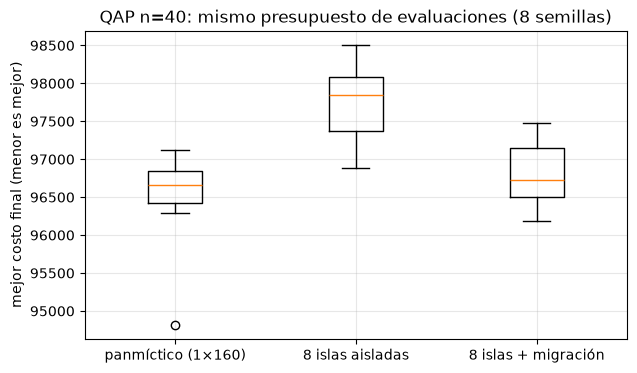

In [17]:
Fi, Di = crear_instancia(40, 21)
res_isl = {"panmíctico (1×160)": [], "8 islas aisladas": [], "8 islas + migración": []}
t0 = time.time()
for s in range(8):
    rng = np.random.default_rng(3000 + s)
    P, C = inicializar_poblacion(Fi, Di, 160, rng); P, C, h = evolucionar(P, C, Fi, Di, 100, rng)
    res_isl["panmíctico (1×160)"].append(C.min())
    for nombre, m in [("8 islas aisladas", 0), ("8 islas + migración", 2)]:
        mejor, tr, _ = islas(Fi, Di, K=8, pop_isla=20, epocas=10, gens_epoca=10, m=m, semilla=3000 + s, memetico=False)
        res_isl[nombre].append(mejor)
print(f"tiempo {time.time()-t0:.0f}s")
tab3 = pd.DataFrame({k: dict(media=np.mean(v), std=np.std(v), mejor=np.min(v)) for k, v in res_isl.items()}).T
print(tab3.round(1).to_string())
a, b = res_isl["8 islas + migración"], res_isl["8 islas aisladas"]; c = res_isl["panmíctico (1×160)"]
print(f"Wilcoxon migración vs aisladas: p = {wilcoxon(a, b).pvalue:.3f} | migración vs panmíctico: p = {wilcoxon(a, c).pvalue:.3f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([res_isl[k] for k in res_isl]); ax.set_xticklabels(list(res_isl)); ax.set_ylabel("mejor costo final (menor es mejor)")
ax.set_title("QAP n=40: mismo presupuesto de evaluaciones (8 semillas)"); plt.show()

**Lectura (contrasta con la tabla impresa).** Comparar *aisladas* contra *con migración* separa el efecto de la subdivisión del efecto de la cooperación. Con 8 semillas y un test de Wilcoxon de potencia limitada hay que ser prudente: reporta las medias y el p-valor impreso, y no extrapoles más allá de esta instancia y estos parámetros. En esta corrida (semillas fijas), la migración mejora a las islas aisladas con significancia a nivel 0.05 y no se distingue del panmíctico, cuyo promedio es similar. Cualitativamente, la subdivisión mantiene diversidad (más exploración) y la migración reparte buenos bloques de construcción; el **intervalo y la cantidad de migrantes** controlan el compromiso entre ambos (migración muy frecuente ≈ población única; nula ≈ ejecuciones independientes).

## Ventajas y limitaciones

| Enfoque | Ventajas | Limitaciones |
|---|---|---|
| Memético (GA+LS) | gran mejora por generación; hijos siempre en óptimo local | más costoso por generación; riesgo de convergencia prematura (poca diversidad); hay que decidir cuánta búsqueda local aplicar y a quién |
| Matheuristic | vecindarios enormes explorados exactamente | requiere buenos subproblemas y un solver; el coste por iteración es alto |
| Multi-start paralelo | trivial de implementar; speedup casi lineal | no hay cooperación: solo reduce la varianza del mejor resultado |
| Maestro-esclavo | no cambia el algoritmo | solo paga con evaluaciones costosas; sincronización por generación |
| Islas | diversidad, tolerancia a fallos, poca comunicación | cambia el algoritmo (nuevos parámetros: tamaño, intervalo, topología); comportamiento difícil de comparar con el secuencial sin cuidado |

## Resumen
- Un híbrido se clasifica por nivel (bajo/alto) y ejecución (relevo/equipo); se combina con otras metaheurísticas, programación matemática, restricciones o ML.
- La evaluación incremental del delta de QAP ($O(n)$, o toda la vecindad vectorizada) se validó contra la recomputación en matrices simétricas y asimétricas.
- El memético mejora al GA por generación y, en estas instancias, también frente a un GA con tiempo comparable (tabla de la sección 4).
- En notebooks, `spawn` exige funciones importables: un módulo temporal creado desde la celda lo resuelve.
- El speedup medido se aleja de Amdahl por sobrecarga, desbalance y sincronización; el modelo de islas paralelo es **idéntico** a su simulación secuencial.

## Ejercicios propuestos
1. Implementa la actualización $O(1)$ de la matriz de deltas tras un swap (Taillard) y compara con recomputar la matriz completa.
2. Varía la probabilidad de aplicar la búsqueda local `pls` (0, 0.1, 0.5, 1) y estudia el compromiso diversidad/intensificación.
3. Cambia la topología de migración (anillo → completa → aleatoria) y mide el efecto en la calidad final.
4. Implementa migración **asíncrona** (cada isla migra sin esperar) y analiza la pérdida de reproducibilidad.
5. Sustituye la enumeración de $k=4$ por un solver exacto más grande (p. ej. ramificación y poda sobre $k=7$) dentro de un LNS completo.
6. Ajusta una regresión de $T(p)$ con un término de sobrecarga lineal en $p$ (modelo USL, *universal scalability law*) y compara con Amdahl.

## Referencias
- Talbi, E.-G. (2002). *A taxonomy of hybrid metaheuristics.* Journal of Heuristics.
- Blum, C., Puchinger, J., Raidl, G. R., Roli, A. (2011). *Hybrid metaheuristics in combinatorial optimization: A survey.* Applied Soft Computing.
- Raidl, G. R. (2006). *A unified view on hybrid metaheuristics.* Hybrid Metaheuristics (LNCS 4030).
- Maniezzo, V., Stützle, T., Voß, S. (eds.) (2010). *Matheuristics: Hybridizing Metaheuristics and Mathematical Programming.* Springer.
- Moscato, P. (1989). *On evolution, search, optimization, genetic algorithms and martial arts: Towards memetic algorithms.* Caltech Concurrent Computation Program Report 826.
- Taillard, É. (1991). *Robust taboo search for the quadratic assignment problem.* Parallel Computing.
- Shaw, P. (1998). *Using constraint programming and local search methods to solve vehicle routing problems.* CP-98.
- Alba, E. (ed.) (2005). *Parallel Metaheuristics: A New Class of Algorithms.* Wiley.
- Amdahl, G. M. (1967). *Validity of the single processor approach to achieving large scale computing capabilities.* AFIPS Spring Joint Computer Conference.
- Gustafson, J. L. (1988). *Reevaluating Amdahl's law.* Communications of the ACM.

In [18]:
import shutil; shutil.rmtree(MOD_DIR, ignore_errors=True)       # limpia el módulo temporal
print(f"Tiempo total de la notebook: {time.time()-t_inicio_notebook:.0f}s")

Tiempo total de la notebook: 176s
